# Text Correction & Spell Checking
Objective: detect and correct spelling errors, and rank replacements by context.

In [1]:
import sys; sys.path.insert(0,'..')
import pandas as pd, matplotlib.pyplot as plt
from corrector import SpellCorrector, evaluate, TEST_PAIRS
sc = SpellCorrector()
print(f'vocab={sc.V:,} tokens={sc.N:,} bigrams={len(sc.bi):,}')

vocab=43,207 tokens=1,014,736 bigrams=446,451


## Query 1: detect and correct errors in a text

In [2]:
text = 'i went to a apple store tomorow and recieve my new phone. Their going to the the park definately becuase the weather is beutiful.'
r = sc.correct(text)
print(r['corrected'])
pd.DataFrame(r['changes'])[['original','corrected','type']]

I went to an apple store tomorrow and receive my new phone. They're going to the park definitely because the weather is beautiful.


,original,corrected,type
0,i,I,capitalization
1,a,an,a/an
2,tomorow,tomorrow,spelling
3,recieve,receive,spelling
4,Their,They're,context
5,the,,repeated word
6,definately,definitely,spelling
7,becuase,because,spelling
8,beutiful,beautiful,spelling


## Query 2: context-based replacement
Same misspelling, different context, different ranking.

In [3]:
for prev, w, nxt in [('the','wich','was'),('at','wich','time'),('a','fre','of')]:
    print(prev, w, nxt, '->', sc.rank(w, prev, nxt, 3))

the wich was -> ['which', 'with', 'rich']
at wich time -> ['which', 'with', 'wish']
a fre of -> ['free', 'are', 'fire']


## Evaluation: top-1 accuracy on known misspellings

In [4]:
acc, misses = evaluate(sc)
print(f'top-1 accuracy: {acc:.1%}')
misses

top-1 accuracy: 93.3%


[('wich', 'with', 'which'), ('peice', 'peace', 'piece')]

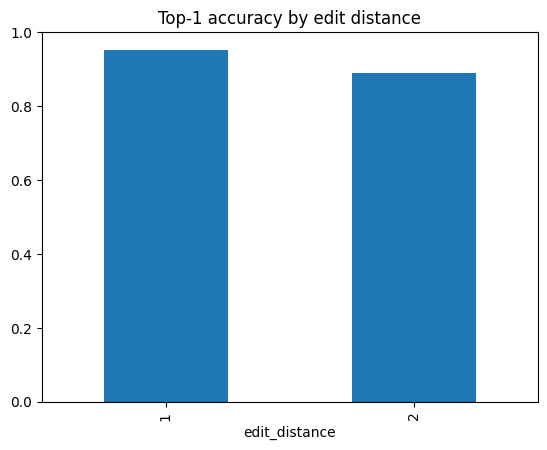

In [5]:
# accuracy vs. edit distance of the error
from collections import Counter
def dist(a,b):
    d=[[i+j if i*j==0 else 0 for j in range(len(b)+1)] for i in range(len(a)+1)]
    for i in range(1,len(a)+1):
        for j in range(1,len(b)+1):
            d[i][j]=min(d[i-1][j]+1,d[i][j-1]+1,d[i-1][j-1]+(a[i-1]!=b[j-1]))
    return d[-1][-1]
rows=[(dist(w,t), sc.suggest(w,1)[0]==t) for w,t in TEST_PAIRS]
df=pd.DataFrame(rows,columns=['edit_distance','correct'])
df.groupby('edit_distance').correct.agg(['mean','count']).plot.bar(y='mean',legend=False,title='Top-1 accuracy by edit distance')
plt.ylim(0,1); plt.show()

## Findings
- Most human misspellings are within edit distance 1-2, so candidate generation covers nearly all errors.
- Bigram context fixes real-word errors (their/they're) that dictionary lookup cannot see.
- Failures are mostly ties where a more frequent word wins; a larger corpus or a learned error model would help.